In [1]:
from pathlib import Path

import numpy as np
from dataeval.data import Filter, Indices, Limit, Shuffle, View
from datamaite import load_ic
from maite_datasets.image_classification import MilitaryVehicles

from dataeval_flow.config import PreprocessingStep

data_root = Path("./data")
MilitaryVehicles(root=data_root, image_set="base", download=True)
MilitaryVehicles(root=data_root, image_set="train", as_datamaite=True)

vehicles = load_ic(data_root / "militaryvehicles_datamaite_train" / "train", dataset_format="huggingface_vision")
index2label = vehicles.metadata.get("index2label", {})

HELD_OUT_NAMES = {"30N6E", "Iskander", "Pantsir-S1", "Rs-24"}
held_out = {i for i, name in index2label.items() if name in HELD_OUT_NAMES}
known_classes = [i for i in sorted(index2label) if i not in held_out]

# Both pools are constructed using View operations.
# You build them in Python here because the classification model trains on the
# labeled pool directly before pipeline execution.
#
# Labeled pool: The twenty known classes only.
labeled_dataset = View(vehicles, [Filter(classes=known_classes), Shuffle(seed=42), Limit(4000)])
labeled_indices = labeled_dataset.resolve_indices()

# Unlabeled pool: The remaining frames, containing Air Defense systems and leftover known types.
pool_dataset = View(vehicles, [Indices(labeled_indices, exclude=True), Shuffle(seed=7), Limit(1500)])

pool_labels = np.array([int(np.argmax(pool_dataset[i][1])) for i in range(len(pool_dataset))])
n_novel = int(np.isin(pool_labels, sorted(held_out)).sum())
print(f"Held out (Air Defense): {sorted(index2label[i] for i in held_out)}")
print(f"Labeled pool:   {len(labeled_dataset)} frames, {len(known_classes)} types")
print(
    f"Unlabeled pool: {len(pool_dataset)} frames, {n_novel} of them Air Defense "
    f"({n_novel / len(pool_dataset) * 100:.0f}%)"
)

/builds/jatic/aria/dataeval-flow/.nox/docs/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Held out (Air Defense): ['30N6E', 'Iskander', 'Pantsir-S1', 'Rs-24']
Labeled pool:   4000 frames, 20 types
Unlabeled pool: 1500 frames, 377 of them Air Defense (25%)


In [2]:
from collections.abc import Mapping
from typing import Any

import numpy as np
from numpy.typing import NDArray
from PIL import Image, ImageFilter


class CorruptedTestDataset:
    """Wraps a MAITE dataset and injects synthetic corruptions into indices 900-999.

    Labels are left untouched throughout, so ground truth stays available for
    verification even though the pixel content at those indices is corrupted.
    """

    _DUPLICATE_OFFSET = 700  # maps index i in [900, 920) to source index i - 700

    def __init__(self, dataset: Any) -> None:
        self._dataset = dataset

    def __len__(self) -> int:
        return len(self._dataset)

    def __getitem__(self, index: int) -> tuple[NDArray[Any], Any, Mapping[str, Any]]:
        if 900 <= index < 920:
            image, _, _ = self._dataset[index - self._DUPLICATE_OFFSET]
            _, target, metadata = self._dataset[index]
            return np.array(image, copy=True), target, metadata

        image, target, metadata = self._dataset[index]

        if 920 <= index < 940:
            image = self._blur(image)
        elif 940 <= index < 960:
            image = self._add_noise(image, seed=index)
        elif 960 <= index < 980:
            image = self._adjust_exposure(image, 100)
        elif 980 <= index < 1000:
            image = self._adjust_exposure(image, -200, halve=True)

        return image, target, metadata

    @staticmethod
    def _blur(image: NDArray[Any]) -> NDArray[Any]:
        hwc = np.transpose(image, (1, 2, 0))  # CHW -> HWC
        blurred = Image.fromarray(hwc, mode="RGB").filter(ImageFilter.GaussianBlur(radius=3))
        return np.transpose(np.array(blurred, dtype=image.dtype), (2, 0, 1))  # back to CHW

    @staticmethod
    def _add_noise(image: NDArray[Any], *, seed: int) -> NDArray[Any]:
        arr = image.astype(np.int16)
        noise = np.random.default_rng(seed).integers(-80, 80, arr.shape, dtype=np.int16)
        return np.clip(arr + noise, 0, 255).astype(image.dtype)

    @staticmethod
    def _adjust_exposure(image: NDArray[Any], delta: int, *, halve: bool = False) -> NDArray[Any]:
        arr = np.clip(image.astype(np.int16) + delta, 0, 255)
        if halve:
            arr = arr // 2
        return arr.astype(image.dtype)


test_dataset = CorruptedTestDataset(pool_dataset)

print(
    "Test data corruption wrapper ready: 20 exact duplicates (900-919), "
    "20 blurred (920-939), 20 noisy (940-959), "
    "20 bright (960-979), 20 dark (980-999)"
)

Test data corruption wrapper ready: 20 exact duplicates (900-919), 20 blurred (920-939), 20 noisy (940-959), 20 bright (960-979), 20 dark (980-999)


In [3]:
import random

import torch
import torch.nn as nn
import torch.nn.functional as F  # noqa: N812
import torchvision

random.seed(42)
torch.manual_seed(42)


class VehicleNet(nn.Module):
    """A frozen pretrained trunk, a learned embedding, and a head over known classes.

    ``embed`` bundles Linear + ReLU so a forward hook captures the activated output:
    the representation the classifier was trained on.
    """

    def __init__(self, num_classes: int) -> None:
        super().__init__()
        trunk = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        trunk.fc = nn.Identity()
        self.trunk = trunk
        self.embed = nn.Sequential(nn.Linear(512, 128), nn.ReLU())
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.embed(self.trunk(x)))


model = VehicleNet(len(known_classes))
for parameter in model.trunk.parameters():
    parameter.requires_grad = False
model.trunk.eval()

_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def _trunk_features(dataset: Any) -> tuple[torch.Tensor, list[int]]:
    """Run the frozen trunk once over a dataset to generate training features for the head."""
    out: list[torch.Tensor] = []
    labels: list[int] = []
    with torch.no_grad():
        for start in range(0, len(dataset), 64):
            batch = []
            for i in range(start, min(start + 64, len(dataset))):
                image, target, _ = dataset[i]
                labels.append(int(np.argmax(target)))
                img = torch.tensor(np.asarray(image), dtype=torch.float32) / 255.0
                img = F.interpolate(img.unsqueeze(0), size=(224, 224), mode="bilinear", align_corners=False)
                batch.append((img.squeeze(0) - _MEAN) / _STD)
            out.append(model.trunk(torch.stack(batch)))
    return torch.cat(out), labels

In [4]:
_remap = {c: k for k, c in enumerate(known_classes)}
features, labeled_labels = _trunk_features(labeled_dataset)
targets = torch.tensor([_remap[c] for c in labeled_labels], dtype=torch.long)

head = nn.Sequential(model.embed, model.classifier)
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
for _epoch in range(40):
    optimizer.zero_grad()
    loss = F.cross_entropy(head(features), targets)
    loss.backward()
    optimizer.step()
model.eval()

accuracy = (head(features).argmax(1) == targets).float().mean().item()
print(f"Head trained: loss={loss.item():.3f}, accuracy on the labeled pool={accuracy * 100:.1f}%")

Head trained: loss=1.677, accuracy on the labeled pool=50.2%


In [5]:
model_path = Path("./models/vehiclenet.pt")
model_path.parent.mkdir(parents=True, exist_ok=True)
torch.save(model, str(model_path))
print(f"Model saved to {model_path}")

Model saved to models/vehiclenet.pt


In [6]:
from dataeval_flow.config import (
    DatasetProtocolConfig,
    PipelineConfig,
    PreprocessorConfig,
    SourceConfig,
    TaskConfig,
)
from dataeval_flow.config.extractors import TorchExtractorConfig
from dataeval_flow.evaluators.quality import DuplicatesConfig, OutliersConfig
from dataeval_flow.steps import CustomWorkflowConfig, StepEntry
from dataeval_flow.workflows.prioritization import PrioritizationWorkflowConfig

ref_dataset = labeled_dataset

# The adaptive bound is lower than the default 3.5, to catch subtler corruptions.
outliers = OutliersConfig(name="outliers", flags=["dimension", "pixel", "visual"], outlier_threshold=("adaptive", 3.0))
duplicates = DuplicatesConfig(name="duplicates", merge_near_duplicates=True)
ranking = PrioritizationWorkflowConfig(
    name="ranking", prioritization={"method": "knn", "k": 5, "order": "hard_first", "policy": "difficulty"}
)


def pruned(prefix: str, source: str) -> list[StepEntry]:
    """`source` without its outliers and its exact duplicates: steps `outliers-<prefix>`, `duplicates-<prefix>` and
    `<prefix>-clean`."""
    plans = {f"duplicates-{prefix}": {"dup_types": ["exact"], "keep": "first"}, f"outliers-{prefix}": {"min_flags": 1}}
    return [
        StepEntry(name=f"outliers-{prefix}", evaluator="outliers", input=source),
        StepEntry(name=f"duplicates-{prefix}", evaluator="duplicates", input=source),
        StepEntry(name=f"{prefix}-clean", transform="remove", input=source, plans=plans),
    ]


workflow = CustomWorkflowConfig(
    name="vehicles_prioritize",
    inputs=["reference", {"name": "pools", "list": True}],
    steps=[
        *pruned("reference", "reference"),
        *pruned("pool", "pools"),
        StepEntry(name="rank", workflow="ranking", input=["reference-clean", "pool-clean"]),
    ],
)

task = TaskConfig(
    name="prioritize_pool",
    workflow="vehicles_prioritize",
    sources=["ref_src", "test_src"],
    extractor="cnn_extractor",
)

In [7]:
config = PipelineConfig(
    max_processes=2,
    datasets=[
        DatasetProtocolConfig(name="ref_ds", dataset=ref_dataset),
        DatasetProtocolConfig(name="test_ds", dataset=test_dataset),
    ],
    preprocessors=[
        PreprocessorConfig(
            name="imagenet",
            steps=[
                PreprocessingStep(step="Resize", params={"size": [224, 224], "antialias": True}),
                PreprocessingStep(step="ToDtype", params={"dtype": "float32", "scale": True}),
                PreprocessingStep(
                    step="Normalize",
                    params={"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
                ),
            ],
        ),
    ],
    sources=[
        SourceConfig(name="ref_src", dataset="ref_ds"),
        SourceConfig(name="test_src", dataset="test_ds"),
    ],
    extractors=[
        TorchExtractorConfig(
            name="cnn_extractor",
            model_path=str(model_path),
            layer_name="embed",
            preprocessor="imagenet",
            batch_size=32,
        ),
    ],
    evaluators=[outliers, duplicates],
    workflows=[ranking, workflow],
    tasks=[task],
)

In [8]:
from dataeval_flow import run_task

result = run_task(config, task, cache_dir=Path("./cache"))

/builds/jatic/aria/dataeval-flow/src/dataeval_flow/_cache.py:273: UserWarning: `height` and `width` were binned automatically ('uniform_width') because no bins were declared. The bin count is derived from the data, so it is not stable across samples and the same factor measured twice may not be comparable. Declare cutoffs with continuous_factor_bins={"height": [...]} to control this.
  export(path)


In [9]:
if not result.success:
    print(f"Workflow failed: {result.errors}")
assert result.success

In [10]:
print(result.report())


  VEHICLES_PRIORITIZE
  Workflow:     vehicles_prioritize (custom workflow)
  Timestamp:    2026-11-12T08:35:12.571171+00:00
  Duration:     95.83s
  Source:       ref_src (ref_ds)
                test_src (test_ds)
  Model:        cnn_extractor (torch)
  Preprocessor: imagenet

  Steps: 8 ran

  No findings to report.

  OUTLIERS · OUTLIERS-REFERENCE
  Item  Flags  Flagged by
  ----  -----  -----------------------
  1         2  size 10000 < 47825
               width 100 < 120.9
  2         2  size 10000 < 47825
               width 100 < 120.9
  12        2  size 10000 < 47825
               width 100 < 120.9
  15        1  zeros 0.07005 > 0.05462
  17        1  kurtosis 7.117 > 5.303
  22        1  kurtosis 5.776 > 5.303
  23        1  size 33660 < 47825
  28        3  entropy 1.003 < 1.16
               kurtosis 17.27 > 5.303
               skew -3.815 < -3.183
  30        2  size 10000 < 47825
               width 100 < 120.9
  31        1  zeros 0.06283 > 0.05462
  … 490 more r

In [11]:
# The page styles its whole document, so the docs show it in an iframe of its own.
import html

from IPython.display import display


def show(page: str, height: int = 560) -> None:
    """*page* in an iframe, so its stylesheet and script stay inside it."""
    frame = (
        f'<iframe srcdoc="{html.escape(page, quote=True)}" title="HTML report" loading="lazy" '
        f'style="width:100%;height:{height}px;border:1px solid #d1d9e0;border-radius:6px"></iframe>'
    )
    display({"text/html": frame}, raw=True)

<iframe srcdoc="<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>vehicles_prioritize</title>
<style>:root { color-scheme: light dark;
 --bg: #ffffff; --card: #ffffff; --soft: #f6f8fa; --ink: #111827; --muted: #6b7280; --rule: #e5e7eb;
 --link: #1d4ed8; --ok: #16a34a; --info: #2563eb; --warning: #d97706; --mark: #dc2626;
 --s0: #2563eb; --s1: #d97706; --s2: #7c3aed; --s3: #16a34a;
 --tag: #eef2ff; --tag-ink: #1e1b4b;
}
@media (prefers-color-scheme: dark) { :root {
 --bg: #0f1115; --card: #171a21; --soft: #1d212a; --ink: #e5e7eb; --muted: #9ca3af; --rule: #2a2f3a;
 --link: #93c5fd; --ok: #22c55e; --info: #60a5fa; --warning: #f59e0b; --mark: #f87171;
 --s0: #60a5fa; --s1: #f59e0b; --s2: #a78bfa; --s3: #22c55e;
 --tag: #232a3d; --tag-ink: #c7d2fe;
} }
body { margin: 0; color: var(--ink); background: var(--bg);
 font: 15px/1.5 system-ui, -apple-system, "Segoe UI", Roboto, "Helvetica Neue", Arial, sans-serif; }
main { max-width: 72rem; margin: 0 auto; padding: 1.5rem; }
a { color: var(--link); }
h1, h2, h3, h4 { margin: 1.25rem 0 0.5rem; line-height: 1.25; }
h1 { font-size: 1.6rem; } h2 { font-size: 1.2rem; } h3 { font-size: 1.05rem; } h4 { font-size: 0.95rem; }
nav.contents { border: 1px solid var(--rule); border-radius: 7px; padding: 0.25rem 1rem; margin-bottom: 1.5rem; }
nav.contents h2 { font-size: 1rem; margin: 0.5rem 0; }
.controls { display: flex; justify-content: flex-end; gap: 0.5rem; margin-bottom: 0.5rem; }
.controls button { font: inherit; font-size: 0.8rem; padding: 0.2rem 0.7rem; cursor: pointer;
 color: var(--ink); background: var(--soft); border: 1px solid var(--rule); border-radius: 4px; }
.report { margin-bottom: 2.5rem; }
.report-head { display: flex; align-items: baseline; gap: 0.75rem; flex-wrap: wrap;
 border-bottom: 2px solid var(--ink); padding-bottom: 0.3rem; }
.report-head h1 { margin: 0; }
dl.fields.provenance { display: grid; grid-template-columns: max-content 1fr; gap: 0.15rem 1rem;
 margin: 0.6rem 0 1.2rem; padding: 0.5rem 0.8rem; background: var(--soft); border-radius: 6px;
 color: var(--muted); font-size: 0.85rem; }
dl.provenance dt { font-weight: 600; color: var(--ink); }
dl.provenance dd { margin: 0; overflow-wrap: anywhere; }
section.section > h2 { border-bottom: 1px solid var(--rule); padding-bottom: 0.2rem; }
details.card, details.panel { background: var(--card); border: 1px solid var(--rule);
 border-left: 4px solid var(--info); border-radius: 7px; padding: 0.3rem 1rem 0.6rem; margin: 0.9rem 0; }
details.card.ok { border-left-color: var(--ok); } details.card.warning { border-left-color: var(--warning); }
details.panel { border-left-color: var(--rule); margin-top: 1.5rem; }
:is(details.card, details.panel) > summary { cursor: pointer; list-style: none; }
:is(details.card, details.panel) > summary::-webkit-details-marker { display: none; }
:is(details.card, details.panel) > summary h2 { display: inline; font-size: 1.1rem; margin: 0; }
:is(details.card, details.panel) > summary::before { content: "▸"; color: var(--muted); margin-right: 0.4rem; }
:is(details.card, details.panel)[open] > summary::before { content: "▾"; }
.brief { font-weight: normal; color: var(--muted); margin-left: 0.5rem; }
.badge { font-size: 0.72rem; font-weight: 700; letter-spacing: 0.02em; border-radius: 1rem; padding: 0.05rem 0.55rem;
 margin-left: 0.5rem; color: #fff; background: var(--info); vertical-align: middle; }
.badge.ok { background: var(--ok); } .badge.warning { background: var(--warning); }
.badge.failed { background: var(--mark); }
code, pre { font-family: ui-monospace, SFMono-Regular, Menlo, Consolas, "DejaVu Sans Mono", monospace; }
code { font-size: 0.9em; background: var(--soft); padding: 0 0.2em; border-radius: 3px; }
pre { background: var(--soft); padding: 0.75rem; overflow-x: auto; font-size: 0.85rem; }
pre code { background: none; padding: 0; }
table { border-collapse: collapse; margin: 0.5rem 0; font-size: 0.85rem; f
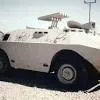
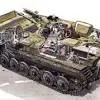
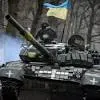
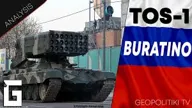
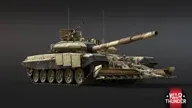
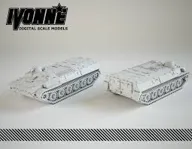
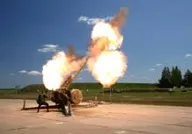
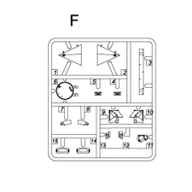
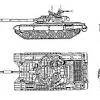
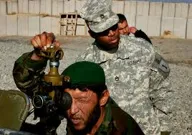
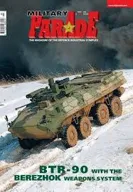
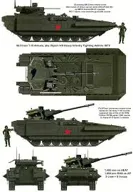
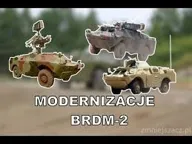
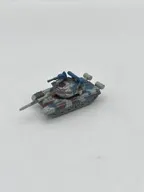
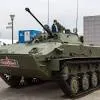
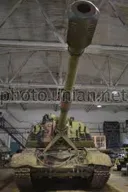
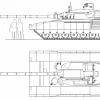
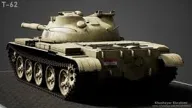
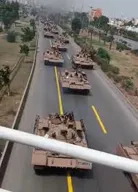
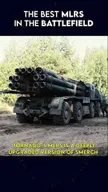
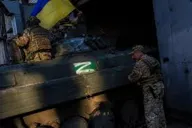
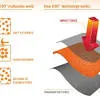
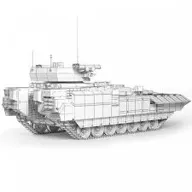
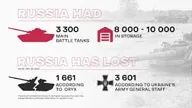
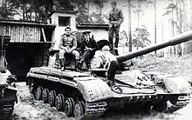
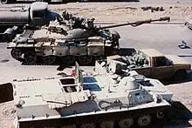
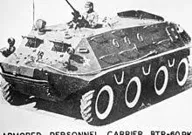
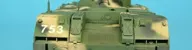
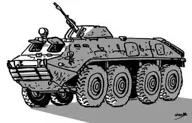
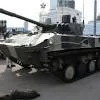
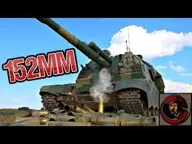
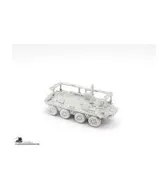
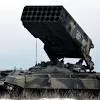
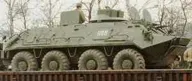
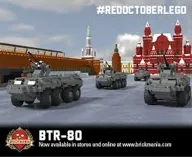
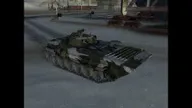
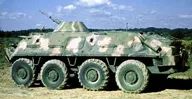
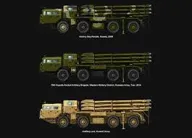
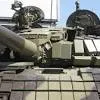
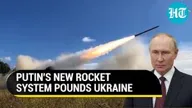
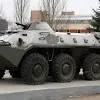
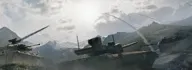
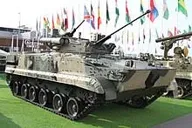
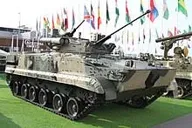
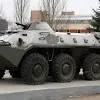
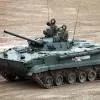
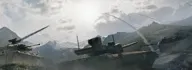
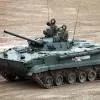
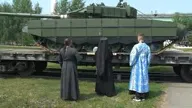
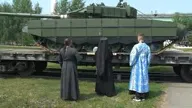
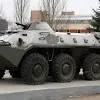
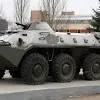
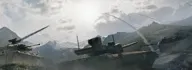
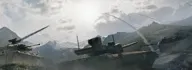
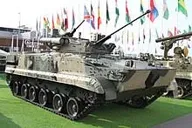
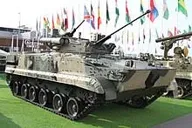
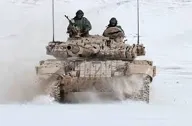
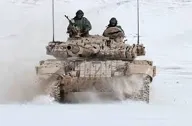
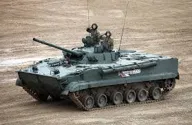
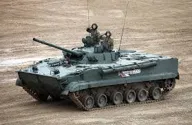
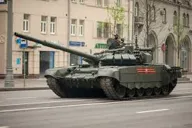
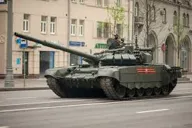
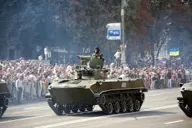
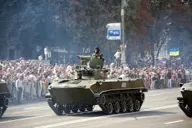
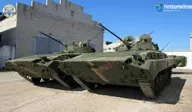
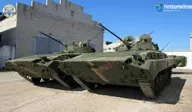
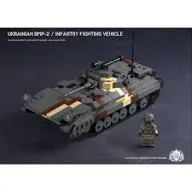
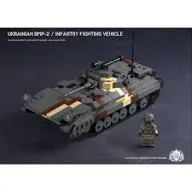
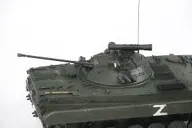
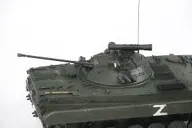
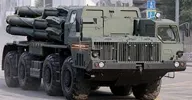
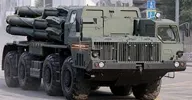
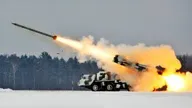
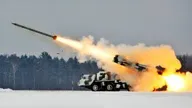
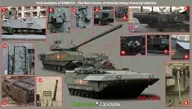
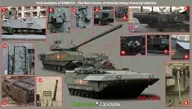
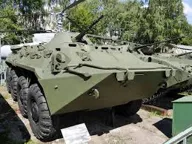
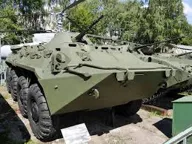
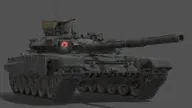
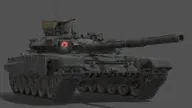
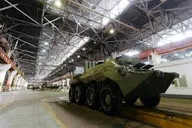
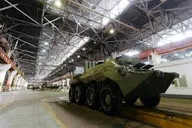
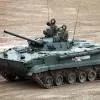
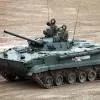
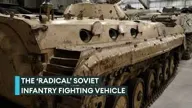
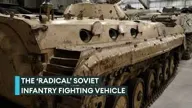
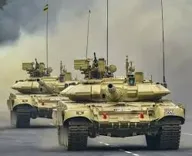
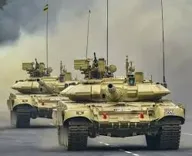
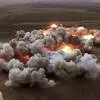
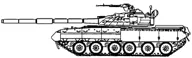
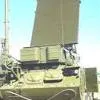
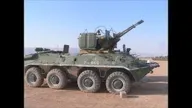
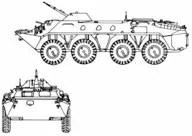
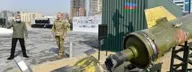
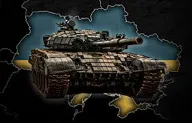
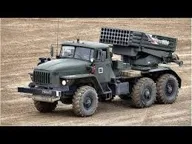
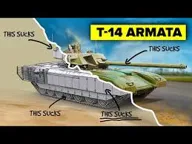
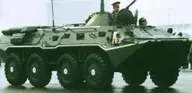
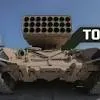
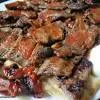
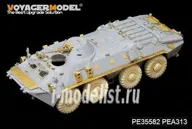
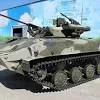
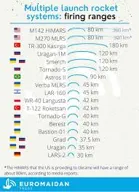
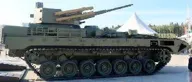
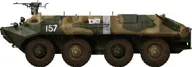
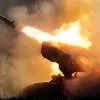
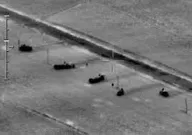
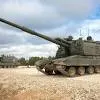
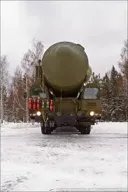
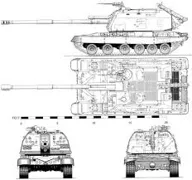
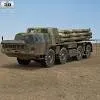
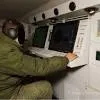
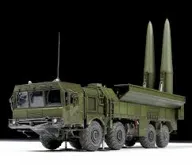
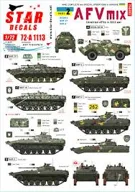
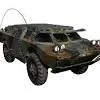
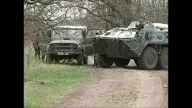
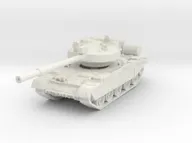
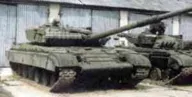
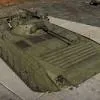
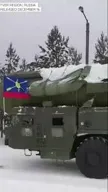
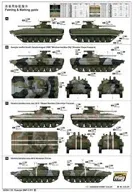
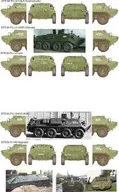
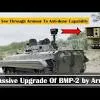
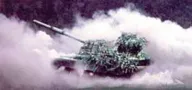
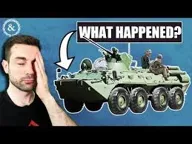
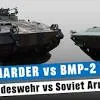
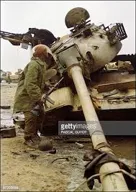
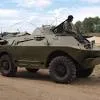
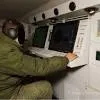
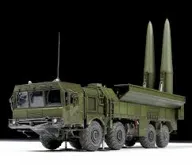
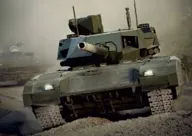
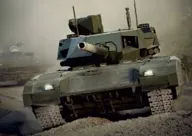
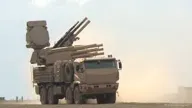
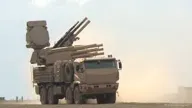
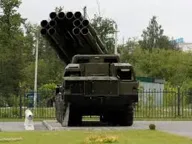
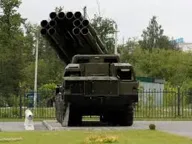
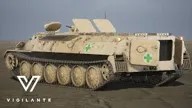
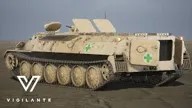
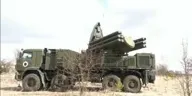
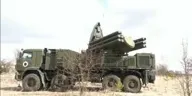
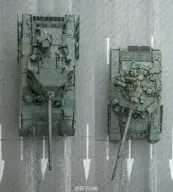
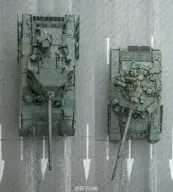
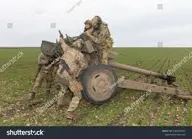
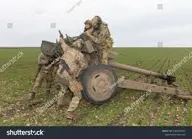
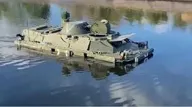
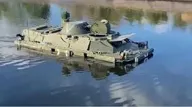
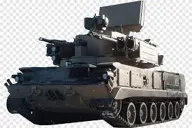
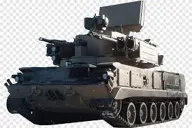
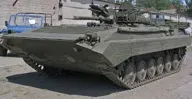
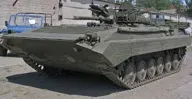
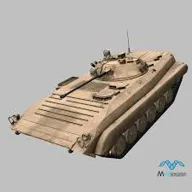
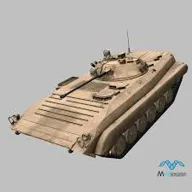
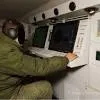
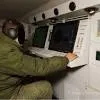
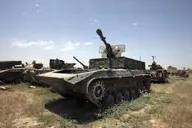
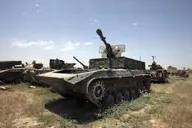
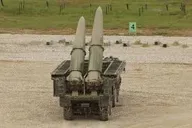
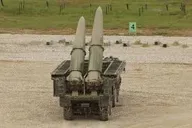
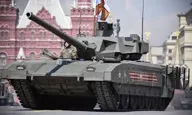
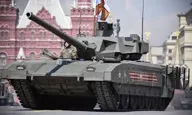
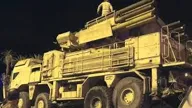
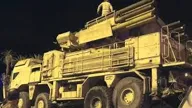
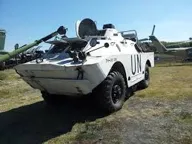
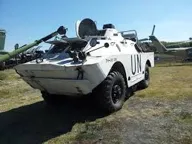
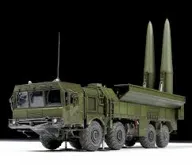
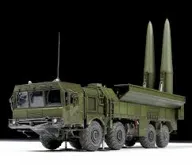
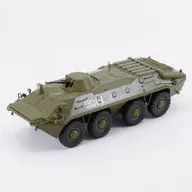
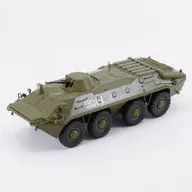
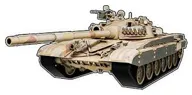
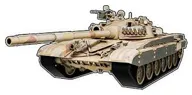
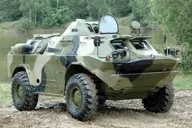
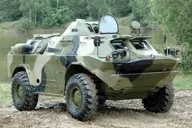
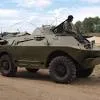
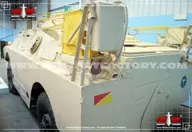
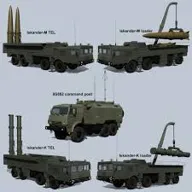
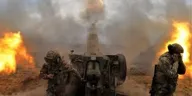
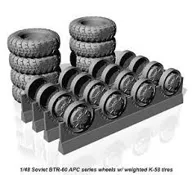
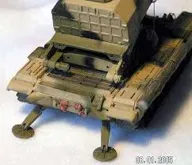
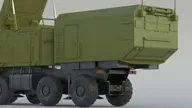
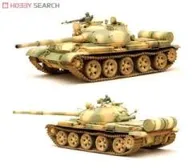
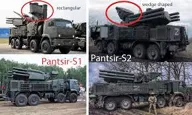
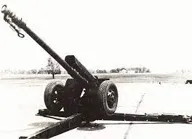
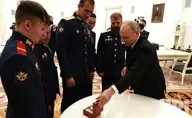
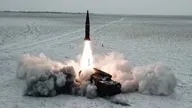
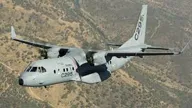
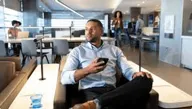
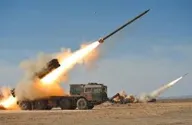
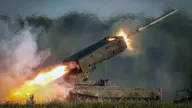
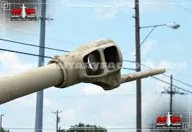
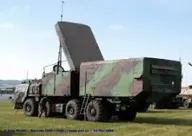
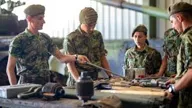
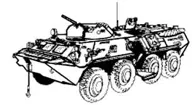
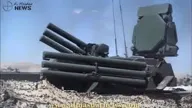
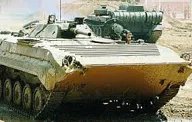
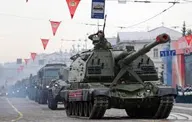
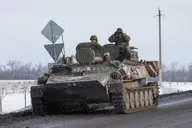
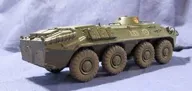
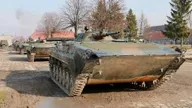
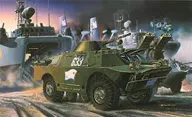
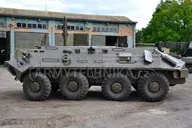
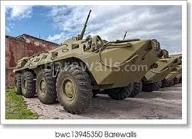
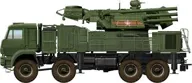
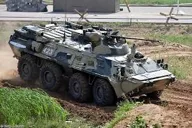
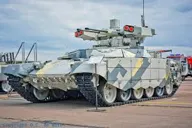
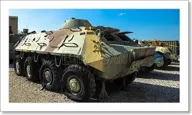
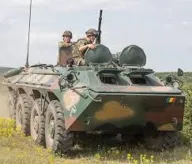
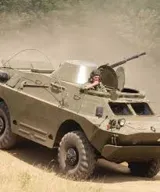
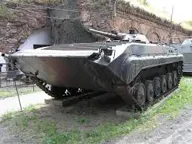
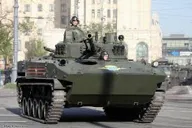
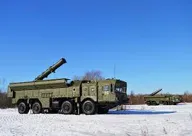
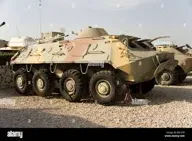
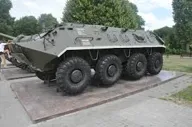
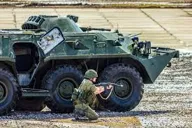

In [12]:
show(result.to_html())

In [13]:
pool_clean = result.steps["pool-clean"].elements["test_src"]
reference_clean = result.steps["reference-clean"]
print(f"Removed from the reference: {reference_clean.details['removed']['items']} frames")
print(f"Removed from the pool:      {pool_clean.details['removed']['items']} frames")

Removed from the reference: 615 frames
Removed from the pool:      237 frames


In [14]:
# Which pool frames were pruned? `pool-clean` holds the frames it kept, by their index in the pool.
kept = pool_clean.output.resolve_indices()
all_test_indices = set(range(len(test_dataset)))
pruned_indices = sorted(all_test_indices - set(kept))
print(f"Pool frames: {len(all_test_indices)} total, {len(kept)} clean, {len(pruned_indices)} pruned")

# Check overlap with known corrupted ranges
corrupted_ranges = {
    "duplicates (900-919)": set(range(900, 920)),
    "blurred (920-939)": set(range(920, 940)),
    "noisy (940-959)": set(range(940, 960)),
    "bright (960-979)": set(range(960, 980)),
    "dark (980-999)": set(range(980, 1000)),
}
pruned_set = set(pruned_indices)
print("\nOverlap with injected corruptions:")
for name, indices in corrupted_ranges.items():
    overlap = pruned_set & indices
    print(f"  {name}: {len(overlap)}/{len(indices)} pruned")

planted = set(range(900, 1000)) | set(range(200, 220))
other_pruned = pruned_set - planted
if other_pruned:
    print(f"  Other frames pruned: {len(other_pruned)} of {len(all_test_indices) - len(planted)}")

Pool frames: 1500 total, 1263 clean, 237 pruned

Overlap with injected corruptions:
  duplicates (900-919): 20/20 pruned
  blurred (920-939): 2/20 pruned
  noisy (940-959): 7/20 pruned
  bright (960-979): 5/20 pruned
  dark (980-999): 20/20 pruned
  Other frames pruned: 181 of 1380


In [15]:
# `selected` holds the pool in ranked order. Its indices count within the cleaned pool, so map them back through
# `pool-clean`'s to index the pool itself.
selected = result.steps["rank/selected"].elements["test_src"].output
top_indices = [kept[i] for i in selected.resolve_indices()]

# `pool_labels` was read straight off the view; the corruption wrapper alters pixels only,
# so a frame's ground-truth label is the same whether or not it was corrupted.
is_novel = np.isin(pool_labels[top_indices], sorted(held_out))
baseline_pct = 100.0 * is_novel.mean()

print(f"Baseline (share of the ranked set): {baseline_pct:.0f}% Air Defense\n")
print(f"{'Budget':>8}  {'Air Defense':>12}  {'vs random':>10}")
for n in (50, 100, 200, 500):
    pct = 100.0 * is_novel[:n].mean()
    print(f"{n:>8}  {pct:>11.0f}%  {pct / baseline_pct:>9.2f}x")

Baseline (share of the ranked set): 26% Air Defense

  Budget   Air Defense   vs random
      50           44%       1.71x
     100           45%       1.75x
     200           41%       1.59x
     500           36%       1.38x


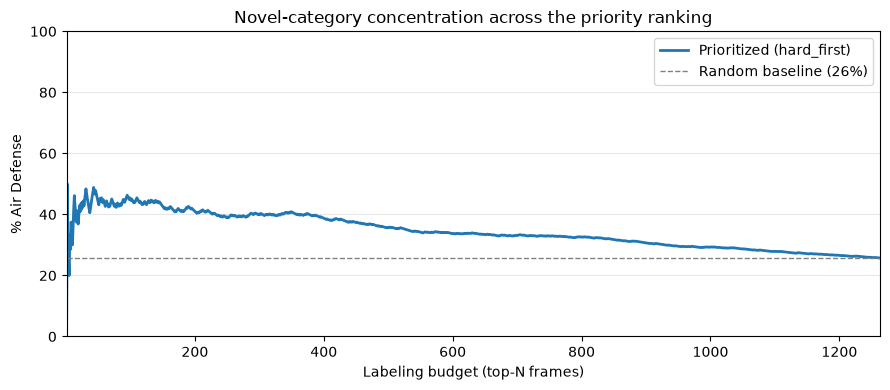

In [16]:
cumulative = np.cumsum(is_novel)
n_items = np.arange(1, len(cumulative) + 1)
novel_pct = 100.0 * cumulative / n_items

try:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(n_items, novel_pct, linewidth=2, label="Prioritized (hard_first)")
    ax.axhline(baseline_pct, color="gray", linestyle="--", linewidth=1, label=f"Random baseline ({baseline_pct:.0f}%)")
    ax.set_xlabel("Labeling budget (top-N frames)")
    ax.set_ylabel("% Air Defense")
    ax.set_title("Novel-category concentration across the priority ranking")
    ax.set_xlim(1, len(cumulative))
    ax.set_ylim(0, max(100, novel_pct[:50].max() * 1.2))
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
except ImportError:
    for n in (50, 100, 200, 500, len(cumulative)):
        print(f"Top {n:4d}: {novel_pct[n - 1]:.0f}% novel")

In [17]:
def _normalized(idx: int) -> torch.Tensor:
    """One pool frame, in the shape the model expects."""
    img = torch.tensor(np.asarray(test_dataset[idx][0]), dtype=torch.float32) / 255.0
    img = F.interpolate(img.unsqueeze(0), size=(224, 224), mode="bilinear", align_corners=False)
    return (img.squeeze(0) - _MEAN) / _STD


# Batched, because the whole pool at 224x224 does not fit in memory at once.
_probs = []
with torch.no_grad():
    for start in range(0, len(top_indices), 32):
        batch = torch.stack([_normalized(i) for i in top_indices[start : start + 32]])
        _probs.append(torch.softmax(model(batch), dim=1))
probabilities = torch.cat(_probs).numpy()

entropy = -(probabilities * np.log(probabilities + 1e-9)).sum(axis=1)
by_entropy = np.argsort(-entropy)
novel_by_entropy = is_novel[by_entropy]

print(f"{'Budget':>8}  {'hard_first':>11}  {'by entropy':>11}  {'baseline':>9}")
for n in (50, 100, 200, 500):
    print(
        f"{n:>8}  {100.0 * is_novel[:n].mean():>10.0f}%  "
        f"{100.0 * novel_by_entropy[:n].mean():>10.0f}%  {baseline_pct:>8.0f}%"
    )

  Budget   hard_first   by entropy   baseline
      50          44%          20%        26%
     100          45%          24%        26%
     200          41%          23%        26%
     500          36%          21%        26%


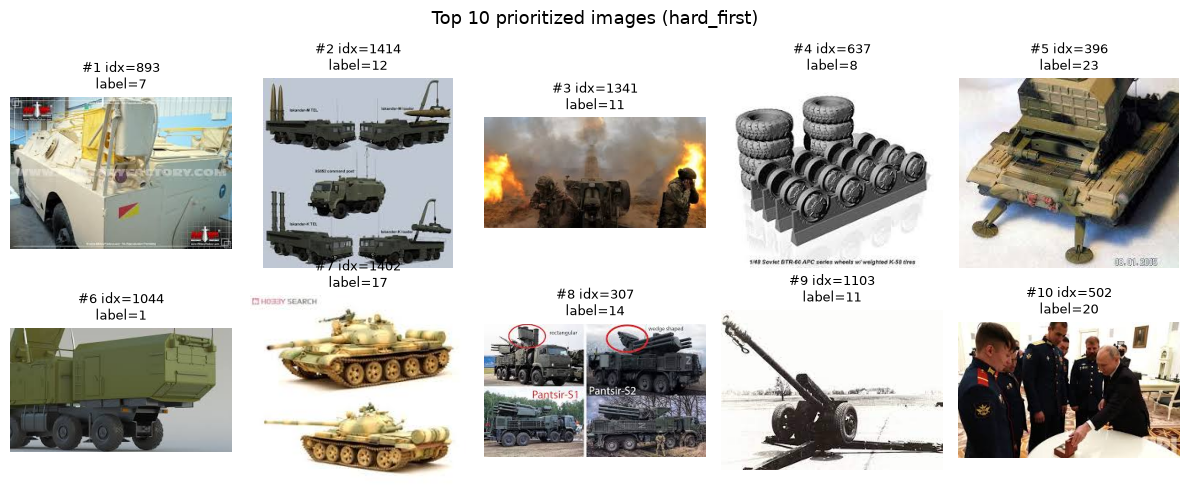

In [18]:
try:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for i, ax in enumerate(axes.flat):
        idx = top_indices[i]
        img, target, _ = test_dataset[idx]
        img_arr = np.transpose(np.asarray(img), (1, 2, 0))  # CHW -> HWC
        label = int(np.argmax(target))
        ax.imshow(img_arr)
        ax.set_title(f"#{i + 1} idx={idx}\nlabel={label}", fontsize=9)
        ax.axis("off")
    fig.suptitle("Top 10 prioritized images (hard_first)", fontsize=13)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Install matplotlib to visualize: pip install matplotlib")

In [19]:
from dataeval_flow.workflows.prioritization import SelectSettings

top_100 = config.model_copy(
    update={"workflows": [ranking.model_copy(update={"select": SelectSettings(n=100)}), workflow]}
)
batch = run_task(top_100, task, cache_dir=Path("./cache")).steps["rank/selected"].elements["test_src"].output
print(f"Selected for labeling: {len(batch)} frames, the first {len(batch)} of the ranking")

Selected for labeling: 100 frames, the first 100 of the ranking
